# ICBP (PT Indofood CBP Sukses Makmur Tbk) - DCF valuation, rebuilt in Python

> **Educational analysis, not investment advice.** Originally a university Financial Management
> assignment; rebuilt and extended in Python.

**What this notebook does**

1. Loads the FY2023-FY2025 financials and every assumption from `data/` and `assumptions.yaml`.
2. Re-implements the course Excel workbook and checks that the Python result matches it.
3. Audits the workbook (formula and modelling issues) with numbers.
4. Builds an extended model: 5-year FCFF projection, WACC, Gordon-growth and exit-multiple terminal values,
   bull/base/bear scenarios, WACC x g heat maps and a reverse DCF.

**Data provenance.** Statement figures are the ones used in the course workbook, whose stated sources are the
ICBP annual reports / IDX filings (plus S&P Global MI via stockanalysis.com and Yahoo Finance). They were
transcribed from that workbook and not re-audited against the filings by the repository author.
The market price (IDR 7,650) is the price recorded in the workbook for May 2026.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from icbp_valuation import load_assumptions, load_financials
from icbp_valuation import plots

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
fin, a = load_financials(), load_assumptions()
price = fin["market"]["share_price_idr"]

## 1. Historical financials (IDR million)

In [2]:
from icbp_valuation.config import historical_table
h = historical_table(fin)
cols = ["revenue", "gross_profit", "ebit", "ebitda", "net_income", "eps", "effective_tax_rate",
        "ebit_margin", "capex", "depreciation_amortization", "total_debt", "cash_and_st_investments",
        "net_debt", "nwc_operating", "wc_total"]
display(h[cols].T.style.format("{:,.3f}", subset=pd.IndexSlice[["effective_tax_rate", "ebit_margin"], :])
        .format("{:,.0f}", subset=pd.IndexSlice[[c for c in cols if c not in ("effective_tax_rate", "ebit_margin", "eps")], :])
        .format("{:,.1f}", subset=pd.IndexSlice[["eps"], :]))

,2023,2024,2025
revenue,"67,909,901","72,597,188","74,850,923"
gross_profit,"25,126,260","26,893,089","26,360,420"
ebit,"14,820,953","16,446,528","15,873,652"
ebitda,"16,515,243","18,232,734","17,733,088"
net_income,"7,013,792","7,207,053","9,224,927"
eps,601.4,618.0,791.0
effective_tax_rate,0.266,0.240,0.223
ebit_margin,0.218,0.227,0.212
capex,"1,823,830","2,162,129","3,634,570"
depreciation_amortization,"1,694,290","1,786,206","1,859,436"


## 2. Verification: Python replica vs the Excel workbook

`replicate_workbook` re-implements the sheet *FCFF & DCF* **exactly as built** (including its questionable choices,
listed in section 3). Each output is compared with the value Excel cached in the original file
(`data/excel_reference.json`, with cell addresses).

In [3]:
from icbp_valuation.verify import compare
cmp = compare(fin, a)
print(f"{cmp['match'].sum()} of {len(cmp)} items match within relative tolerance {a['verification']['relative_tolerance']:.0e}")
print(f"Worst relative difference: {cmp['rel_diff'].max():.2e}")
show = cmp[cmp["item"].isin(["fcff 2025", "wacc", "firm_value", "equity_value", "intrinsic_value_per_share"])]
display(show.style.format({"python": "{:,.6f}", "excel": "{:,.6f}", "abs_diff": "{:.2e}", "rel_diff": "{:.1e}"}))

26 of 26 items match within relative tolerance 1e-09
Worst relative difference: 2.96e-10


,item,excel_cell,python,excel,abs_diff,rel_diff,match
8,fcff 2025,FCFF & DCF!D20,"5,469,915.186353","5,469,915.186000",3.53e-04,6.5e-11,True
16,wacc,FCFF & DCF!B46,0.072641,0.072641,1.19e-12,1.6e-11,True
19,firm_value,FCFF & DCF!B54,"253,675,534.848834","253,675,534.800000",4.88e-02,1.9e-10,True
21,equity_value,FCFF & DCF!B56,"237,866,834.848834","237,866,834.800000",4.88e-02,2.1e-10,True
23,intrinsic_value_per_share,FCFF & DCF!B58,"20,396.744542","20,396.744540",2.00e-06,9.8e-11,True


The replica reproduces Excel to floating-point precision (differences of about 1e-9 IDR come from Excel's cached
values being stored with ~15 significant digits). The workbook's headline - **IDR 20,397 per share, +167% vs the
IDR 7,650 price** - is therefore *correctly computed from its own assumptions*. The problems are in the
assumptions and structure, not the arithmetic.

## 3. Audit of the workbook

In [4]:
from icbp_valuation.audit import audit_findings
aud = audit_findings(fin, a)
pd.set_option("display.max_colwidth", 400)
for i, r in aud.iterrows():
    print(f"[{i+1}] {r.area}\n    Finding : {r.finding}\n    Workbook: {r.workbook}\n    Recomputed: {r.recomputed}\n    Impact  : {r.impact}\n")

[1] DCF / NWC
    Finding : Change in 'NWC' is built from total current assets less total current liabilities, so it includes cash, short-term investments and short-term debt (financing items). FY2025 change in working capital is dominated by cash build-up.
    Workbook: dNWC FY2025 = 5,094,940
    Recomputed: operating dNWC = 1,526,322
    Impact  : FY2025 FCFF 5,469,915 -> 9,038,533 (IDR mn)

[2] DCF / NWC
    Finding : FY2023 change in NWC subtracts a hard-coded, unsourced FY2022 NWC of 21,036,430 inside formula 'FCFF & DCF'!B19. FY2023 FCFF is therefore not reproducible from the data.
    Workbook: FCFF FY2023 = 5,476,825
    Recomputed: not computable without FY2022 balance sheet
    Impact  : Does not drive the headline value (FY2025 base) but shows in the FCFF growth average.

[3] DCF / equity bridge
    Finding : Equity value = EV - net debt only. Consolidated FCFF includes 100% of subsidiaries, so the non-controlling interest must be deducted; investments in associates (outsid

Two of these matter most for the valuation: (1) the change in "NWC" includes cash and debt, which *understates*
FCFF (FY2025: 5.47 tn in the workbook vs 9.04 tn with operating NWC), and (2) a 5% perpetual growth rate against a
7.26% WACC makes the value extremely fragile. They push in opposite directions, which is why the walk in
section 8 is informative.

## 4. Cost of capital (CAPM)

In [5]:
from icbp_valuation.dcf import run_scenario, replicate_workbook
rep = replicate_workbook(fin, a)
base = run_scenario(fin, a, "base")
w = base["wacc_detail"]
pd.DataFrame({
    "Workbook (effective tax)": [rep["wacc_detail"].risk_free, rep["wacc_detail"].beta, rep["wacc_detail"].erp,
                                 rep["cost_of_equity"], rep["pretax_cost_of_debt"], rep["wacc_detail"].tax_rate,
                                 rep["after_tax_cost_of_debt"], rep["weight_equity"], rep["weight_debt"], rep["wacc"]],
    "Extended (22% statutory)": [w.risk_free, w.beta, w.erp, w.cost_of_equity, w.pretax_cost_of_debt, w.tax_rate,
                                 w.after_tax_cost_of_debt, w.weight_equity, w.weight_debt, w.wacc],
}, index=["Risk-free (BI repo)", "Beta", "ERP", "Cost of equity", "Pre-tax cost of debt", "Tax rate",
          "After-tax cost of debt", "Weight equity (market)", "Weight debt (book)", "WACC"]).style.format("{:.4f}")

,Workbook (effective tax),Extended (22% statutory)
Risk-free (BI repo),0.0475,0.0475
Beta,0.6000,0.6000
ERP,0.0750,0.0750
Cost of equity,0.0925,0.0925
Pre-tax cost of debt,0.0454,0.0454
Tax rate,0.2226,0.2200
After-tax cost of debt,0.0353,0.0354
Weight equity (market),0.6529,0.6529
Weight debt (book),0.3471,0.3471
WACC,0.0726,0.0727


Extended base case adds a **+2.0 pp judgement** to the computed WACC (`wacc_adjustment` in `assumptions.yaml`).
Reason: the risk-free proxy is a policy rate and beta 0.60 is low, so 7.3% is thin for a rupiah cash-flow stream.
This is an assumption, not a fact - set it to 0 to see the workbook-consistent discount rate, and see the heat maps
for the full range.

## 5. FCFF projection (base case)

,Revenue,EBIT,NOPAT,D&A,Capex,dNWC,FCFF,EBITDA
year,,,,,,,,
2026,"78,593","16,898","13,180","1,965","3,144",392,"11,610","18,862"
2027,"82,523","17,742","13,839","2,063","3,136",424,"12,342","19,806"
2028,"86,237","18,541","14,462","2,156","3,105",401,"13,112","20,697"
2029,"90,117","19,375","15,113","2,253","3,154",419,"13,792","21,628"
2030,"93,722","20,150","15,717","2,343","3,280",389,"14,391","22,493"


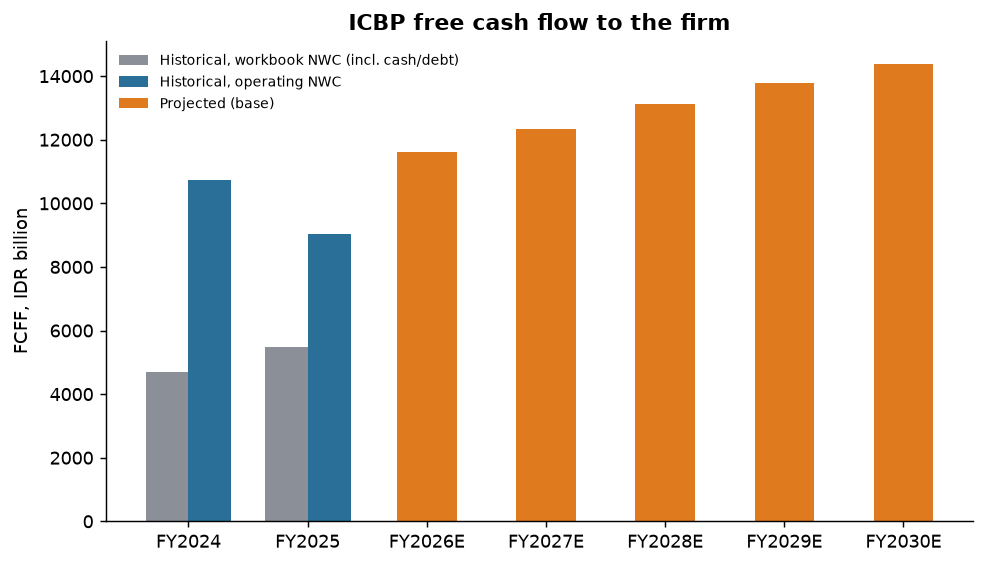

In [6]:
proj = base["projection"].copy()
display((proj / 1e3).rename(columns={"revenue": "Revenue", "ebit": "EBIT", "nopat": "NOPAT", "da": "D&A",
        "ebitda": "EBITDA", "capex": "Capex", "nwc": "Operating NWC", "delta_nwc": "dNWC", "fcff": "FCFF"})
        [["Revenue", "EBIT", "NOPAT", "D&A", "Capex", "dNWC", "FCFF", "EBITDA"]].style.format("{:,.0f}")
        .set_caption("IDR billion"))
display(Image(plots.plot_fcff(fin, a, base)))

## 6. Valuation: Gordon growth and exit multiple, by scenario

scenario,base,bull,bear
WACC,9.3%,8.3%,10.3%
g,4.0%,4.5%,3.0%
exit EV/EBITDA,7.0x,8.5x,5.5x
"EV (Gordon, IDR bn)","232,309","370,165","142,739"
Value/share Gordon (IDR),"17,301","29,122","9,621"
Value/share exit-mult (IDR),"10,330","14,836","6,428"
Headline value/share (IDR),"13,816","21,979","8,025"
Headline upside vs price,80.6%,187.3%,4.9%
Upside vs price (Gordon),126.2%,280.7%,25.8%
Upside vs price (exit-mult),35.0%,93.9%,-16.0%


Market price: IDR 7,650   |   market-implied EV/EBITDA (incl. NCI, less associates): 6.75x


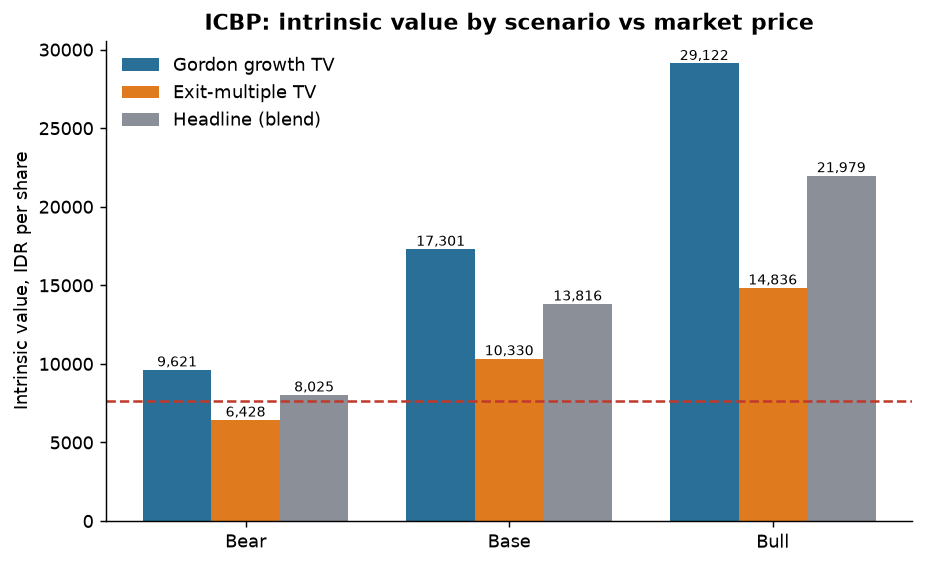

In [7]:
from icbp_valuation.dcf import run_all_scenarios, scenario_table, market_implied_ev_ebitda
res = run_all_scenarios(fin, a)
st = scenario_table(res)
pct = ["WACC", "g", "Upside vs price (Gordon)", "Upside vs price (exit-mult)", "Headline upside vs price", "TV share of EV (Gordon)"]
display(st.T.style.format("{:,.0f}").format("{:.1%}", subset=pd.IndexSlice[pct, :])
        .format("{:.1f}x", subset=pd.IndexSlice[["exit EV/EBITDA", "Implied exit multiple"], :]))
print(f"Market price: IDR {price:,.0f}   |   market-implied EV/EBITDA (incl. NCI, less associates): {market_implied_ev_ebitda(fin):.2f}x")
display(Image(plots.plot_scenarios(res, price)))

**Reading the numbers.** The Gordon-growth value is far above the exit-multiple value in every scenario. The reason is
visible in the "Implied exit multiple" row: the Gordon terminal value is equivalent to 9-18x EBITDA, while ICBP
trades at about 7x. The headline is therefore a 50/50 blend (`blend_weight_gordon`), and neither method should be read
as a point estimate.

## 7. Sensitivity heat maps (base case)

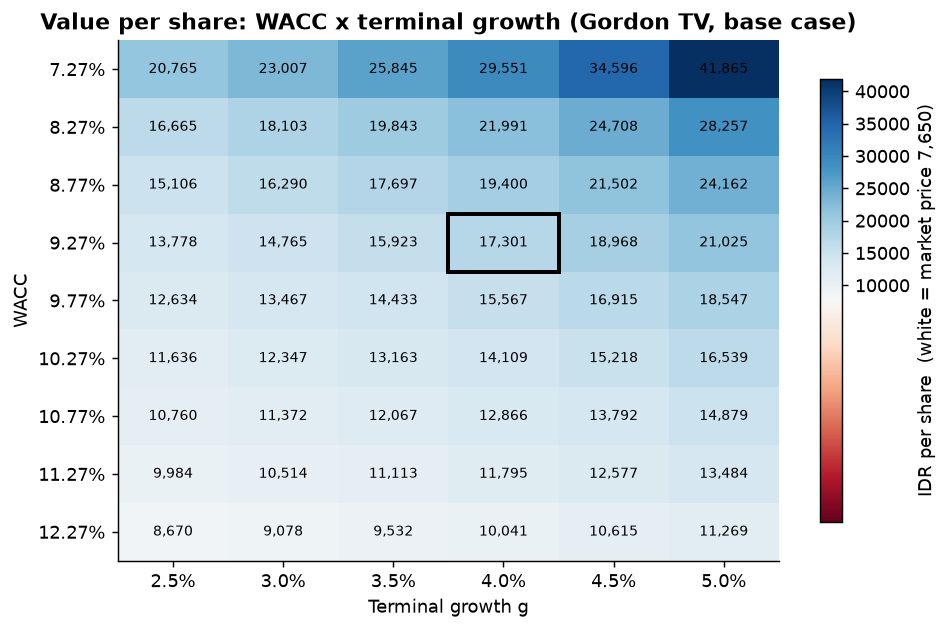

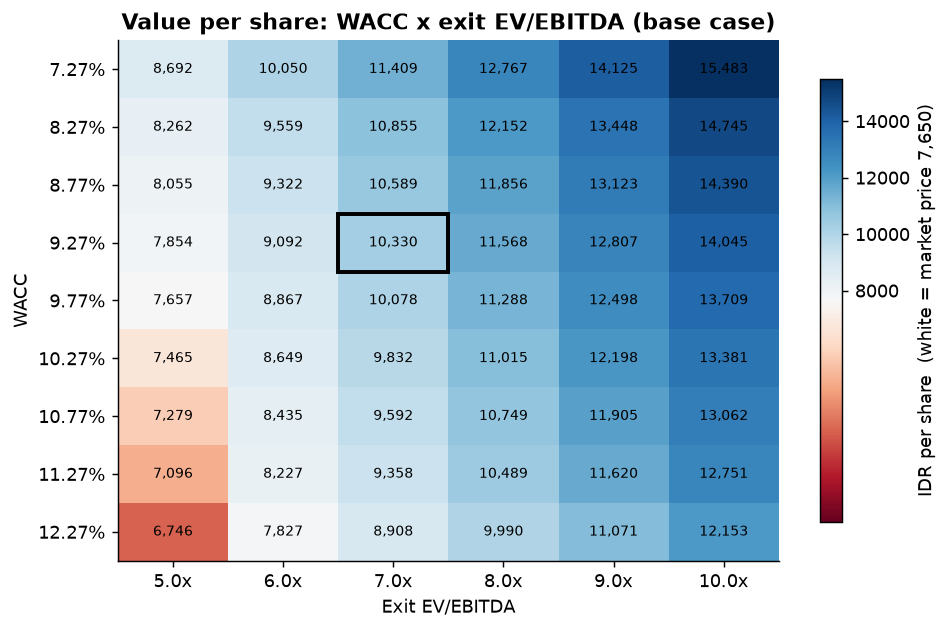

In [8]:
from icbp_valuation.dcf import sensitivity_wacc_g, sensitivity_wacc_exit
g1, g2 = sensitivity_wacc_g(fin, a), sensitivity_wacc_exit(fin, a)
bi = a["sensitivity"]["wacc_deltas"].index(0.0)
display(Image(plots.plot_heatmap(g1, price, "Value per share: WACC x terminal growth (Gordon TV, base case)",
        "Terminal growth g", "heatmap_wacc_g.png", (bi, a["sensitivity"]["terminal_growth"].index(0.04)))))
display(Image(plots.plot_heatmap(g2, price, "Value per share: WACC x exit EV/EBITDA (base case)",
        "Exit EV/EBITDA", "heatmap_wacc_exit_multiple.png", (bi, a["sensitivity"]["exit_multiples"].index(7.0)))))

### Reverse DCF - what discount rate does the market price imply?

In [9]:
from icbp_valuation.dcf import implied_wacc
w_g = implied_wacc(fin, a, method="gordon")
w_x = implied_wacc(fin, a, method="exit_multiple")
print(f"Base-case drivers, Gordon TV  : price IDR {price:,.0f} implies WACC = {w_g:.2%}")
print(f"Base-case drivers, exit-mult. : price IDR {price:,.0f} implies WACC = {w_x:.2%}")
print(f"Computed WACC {base['computed_wacc']:.2%}; base case uses {base['wacc']:.2%}")

Base-case drivers, Gordon TV  : price IDR 7,650 implies WACC = 14.18%
Base-case drivers, exit-mult. : price IDR 7,650 implies WACC = 15.37%
Computed WACC 7.27%; base case uses 9.27%


At the base operating assumptions the market price is consistent with a discount rate of roughly 14-15%
(under either terminal method), versus 9.3% in the base case. Either the market is pricing in much weaker growth or
margins than the base case, or it demands a much higher return - or this simple model is too generous.
That tension is the main result, and it is more informative than the point estimate.

## 8. Walk from the Excel value to the extended model

,step,value_per_share,change,vs_price
0,0. Excel as built (workbook),"20,397",+nan,+167%
1,"1. NWC excludes cash, ST investments and debt","34,588","+14,191",+352%
2,"2. Equity bridge: less NCI, plus associates","33,325","-1,263",+336%
3,3. Terminal growth 5% -> 4.0%,"22,075","-11,249",+189%
4,"4. 5-yr explicit projection, normalised terminal, 22% tax","29,551","+7,475",+286%
5,5. Discount-rate realism adjustment (+2.0pp on WACC),"17,301","-12,250",+126%
6,6. Headline = blend of Gordon and exit-multiple TV,"13,816","-3,486",+81%


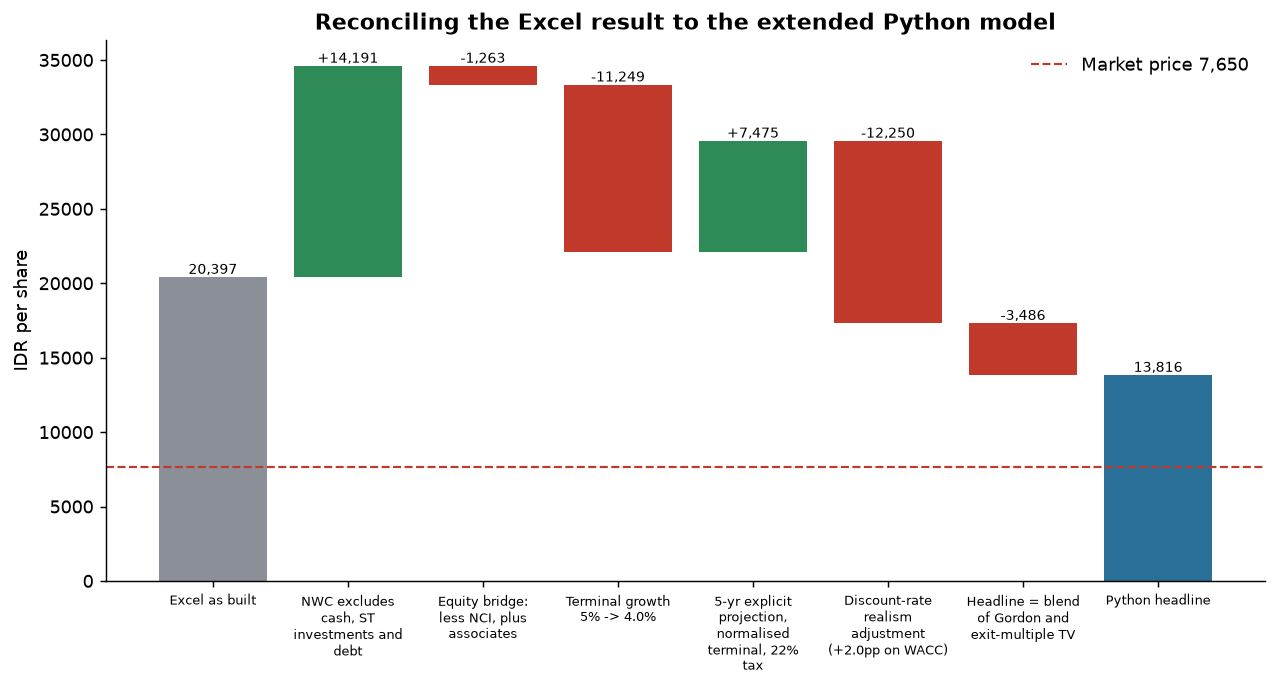

In [10]:
from icbp_valuation.dcf import bridge_walk
walk = bridge_walk(fin, a)
display(walk.style.format({"value_per_share": "{:,.0f}", "change": "{:+,.0f}", "vs_price": "{:+.0%}"}))
display(Image(plots.plot_bridge(walk, price)))

Order matters (effects interact), so treat each step as indicative. Take-away: the workbook's 20,397 is the net of a
large conservative error (NWC definition, +14k) and large aggressive choices (g = 5%, low WACC).

## 9. Limitations

- Inputs are transcribed from a course workbook and not re-verified against filings; FY2023/FY2024 balance sheets do not balance.
- Equity bridge uses **book** NCI and associates; leases, pensions and minority put options are ignored.
- Valuation date is 31 Dec 2025 while the price is May 2026 (no roll-forward).
- CAPM inputs are carried from the workbook; the +2.0 pp WACC adjustment and all scenario drivers are analyst judgements.
- Single-company model; no peer-multiple or regression work; no forward-looking guidance from management.

*Educational analysis, not investment advice.*